In [1]:
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


# 02. Volatility and drawdowns: how rough was the ride?

Volatility is a measure of how much prices jump around. Think of it as
bumpiness. A calm road has low volatility. A road full of potholes has
high volatility. In this notebook we use rolling volatility. Rolling
means we look at a moving window, here 30 trading days, and we measure
the spread of daily returns inside that window. We then annualize it,
which means we scale it up to a yearly number so years are comparable.
The scaling uses the square root of 252, because there are about 252
trading days in a year.

A drawdown is a fall from a previous peak. If the index peaked at 100
and later fell to 80, the drawdown is minus 20 percent. An underwater
chart plots that drawdown over time. When the line is at zero, the
market is at a new peak. When it is below zero, the market is still
under water, meaning it has not yet recovered its old peak.

The VIX is a separate index, published by Cboe, that reflects what
options traders expect for swings in the next 30 days. It is not a
prediction of direction. A high VIX means traders expect big moves, up
or down. A low VIX means they expect calm.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
ROOT = Path("..").resolve()
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"
print("Charts will be saved to:", CHARTS)

Charts will be saved to: /home/hatch/workspace/repo-builds/finance-analytics/charts


In [3]:
sp = pd.read_csv(PROC / "sp500_daily.csv", parse_dates=["date"])
major = pd.read_csv(PROC / "sp500_major_drawdowns.csv")
vix = pd.read_csv(PROC / "vix_daily.csv", parse_dates=["date"])
print("Major drawdowns, falls of 20 percent or more:")
print(major.to_string(index=False))
print()
print("Highest 30 day rolling volatility in the file:")
row = sp.loc[sp["rolling_vol_30d"].idxmax()]
print(row["date"].date(), round(row["rolling_vol_30d"] * 100, 1), "percent annualized")
print("Highest VIX close in the file:")
row = vix.loc[vix["vix"].idxmax()]
print(row["date"].date(), row["vix"])

Major drawdowns, falls of 20 percent or more:
 peak_date trough_date recovery_date  depth_pct  recovered  decline_months  recovery_months  total_months  recovery_score
2007-10-09  2009-03-09    2013-03-28     -56.78       True            17.0             48.6          65.6             8.6
2000-03-24  2002-10-09    2007-05-30     -49.15       True            30.5             55.7          86.2             9.0
1973-01-11  1974-10-03    1980-07-17     -48.20       True            20.7             69.4          90.1             7.6
2020-02-19  2020-03-23    2020-08-18     -33.92       True             1.1              4.9           5.9            46.9
1987-08-25  1987-12-04    1989-07-26     -33.51       True             3.3             19.7          23.0            25.2
1980-11-28  1982-08-12    1982-11-03     -27.11       True            20.4              2.7          23.2            59.5
1970-01-05  1970-05-26    1971-01-19     -25.86       True             4.6              7.8         

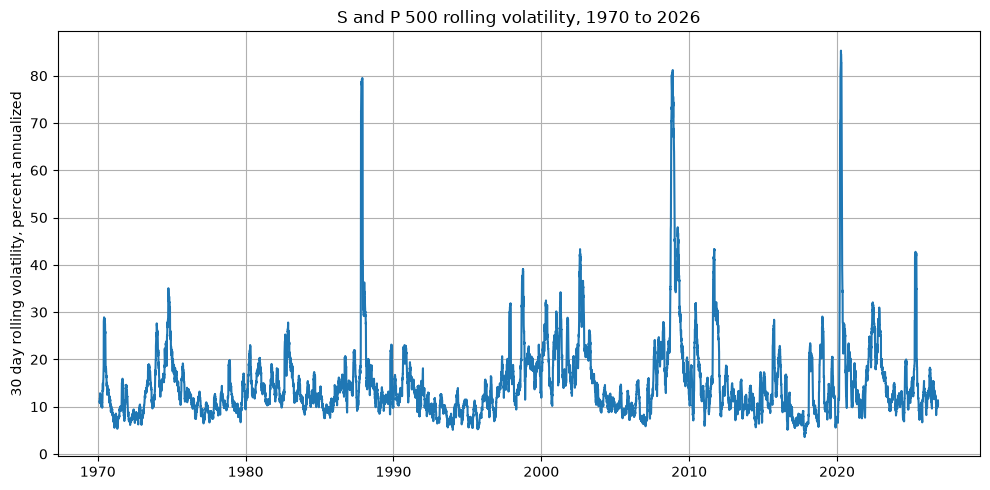

In [4]:
fig, ax = plt.subplots()
ax.plot(sp["date"], sp["rolling_vol_30d"] * 100)
ax.set_ylabel("30 day rolling volatility, percent annualized")
ax.set_title("S and P 500 rolling volatility, 1970 to 2026")
plt.tight_layout()
plt.savefig(CHARTS / "02_rolling_vol.png", dpi=150)
plt.show()

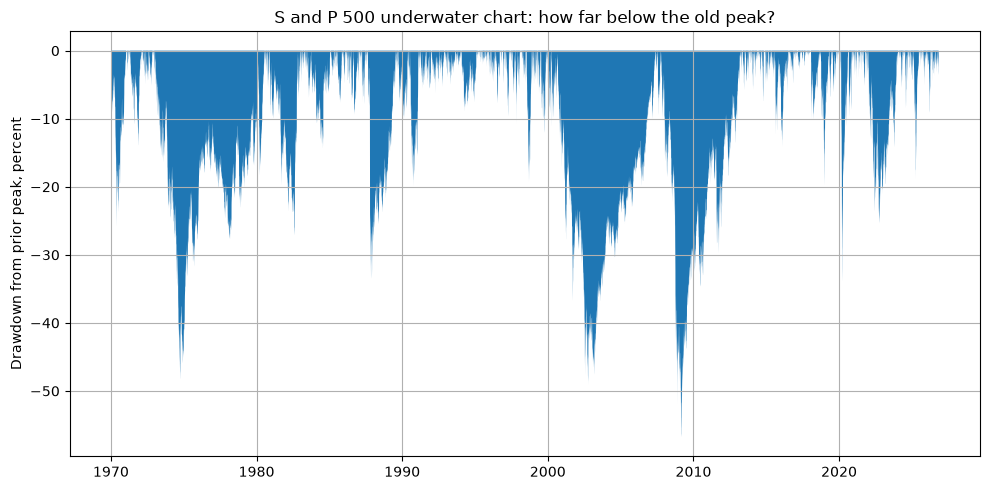

In [5]:
fig, ax = plt.subplots()
ax.fill_between(sp["date"], sp["drawdown"] * 100, 0)
ax.set_ylabel("Drawdown from prior peak, percent")
ax.set_title("S and P 500 underwater chart: how far below the old peak?")
plt.tight_layout()
plt.savefig(CHARTS / "02_drawdown_underwater.png", dpi=150)
plt.show()

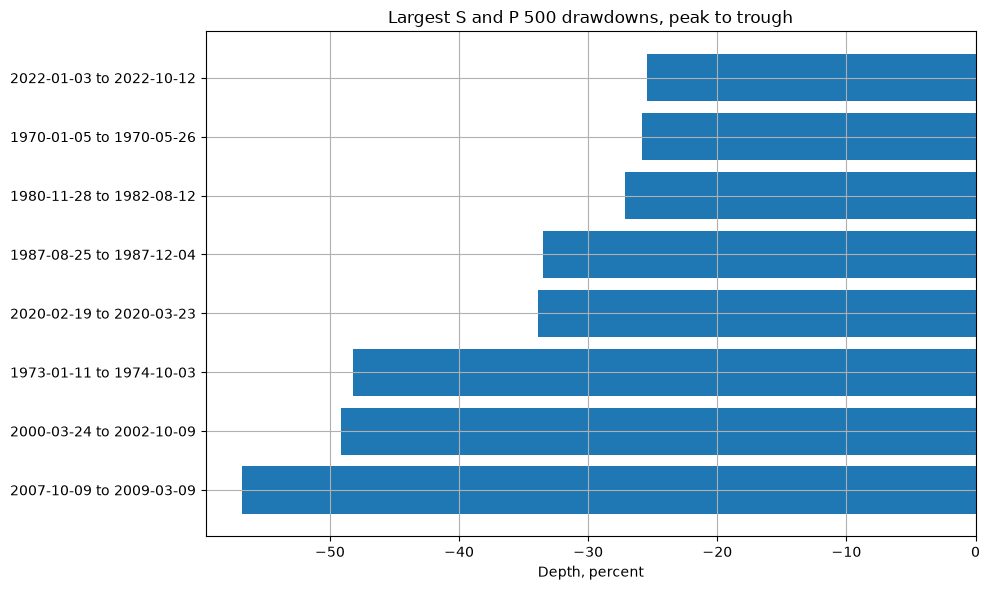

In [6]:
plot_major = major.sort_values("depth_pct")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_major["peak_date"] + " to " + plot_major["trough_date"], plot_major["depth_pct"])
ax.set_xlabel("Depth, percent")
ax.set_title("Largest S and P 500 drawdowns, peak to trough")
plt.tight_layout()
plt.savefig(CHARTS / "02_major_drawdowns.png", dpi=150)
plt.show()

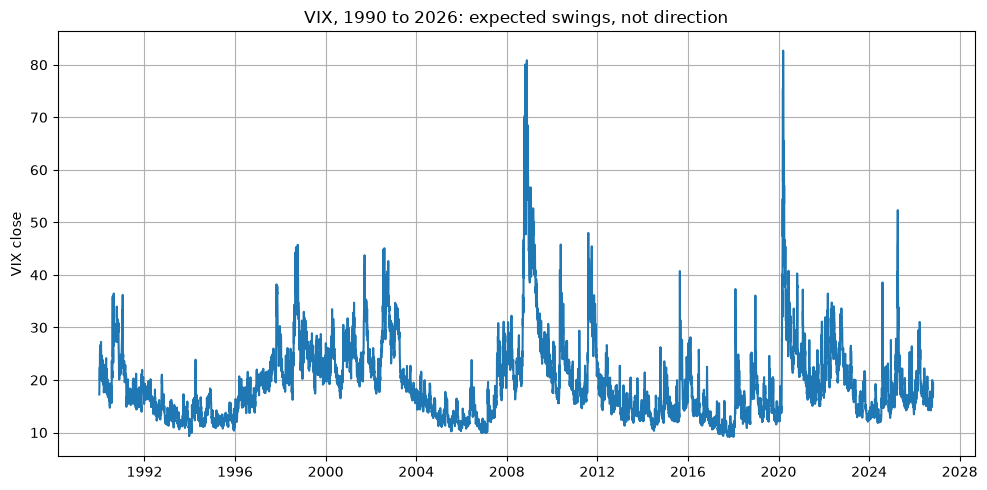

In [7]:
fig, ax = plt.subplots()
ax.plot(vix["date"], vix["vix"])
ax.set_ylabel("VIX close")
ax.set_title("VIX, 1990 to 2026: expected swings, not direction")
plt.tight_layout()
plt.savefig(CHARTS / "02_vix.png", dpi=150)
plt.show()

## What we learned, in plain words

The deepest fall in this file was the 2007 to 2009 episode, down about
56.8 percent from peak to trough, and it took until March 2013 to get
back to the old peak. The fastest deep fall was in early 2020, down
about 33.9 percent in about a month, then recovered in about 5 months.
Those two facts together are the lesson: some falls are deep and slow
to heal, others are sharp and fast to heal, and you cannot tell which
kind you are in while it is happening.

Volatility also clusters. Calm years tend to follow calm years, and
rough months tend to follow rough months. The highest VIX close in the
file was 82.69 on March 16, 2020. In March 2023, during the SVB week, the
VIX rose only to about 26.5. That contrast matters for the SVB chapter:
the broad market was stressed in March 2023, but it was not at 2020 or
2008 levels of panic.